# Stage 05 — Categorical Encoding & Multicollinearity

## Objective

Compare five encodings of the same nominal information and assess dimension, unknown-level
behavior and multicollinearity. Use race, payer, state, Region and Division; ZIP is only a
group key. Clinical code/text/treatment and constant gender remain excluded.

## Methodology

All 8,173 original training rows are retained. Missing values use an explicit reserved token;
no rare pooling or literal-code normalization occurs. State has >20 observed categories and
qualifies for binary encoding. No genuine ordinal ordering is verified: Ordinal is an illustration.

| Method | Fixed rule / limitation |
|---|---|
| One-Hot | Most frequent nonmissing train reference; lexical tie-break; unknown=all zero |
| Ordinal | Lexical identifiers; unknown=−1; no meaningful numerical distance |
| Target OOF | Five label-independent shuffled ZIP GroupKFold splits, seed=42, alpha=10 |
| Binary hybrid | State bits; unknown code=0, missing=1; same low-cardinality One-Hot blocks |
| Frequency | Training relative count; unknown=0; equal-frequency categories can collide |

$$
\widehat p_{c,-f}=\frac{s_{c,-f}+\alpha\mu_{-f}}{n_{c,-f}+\alpha},\qquad\alpha=10.
$$

$$
B_r(c)=\left\lfloor\frac{\operatorname{code}(c)}{2^r}\right\rfloor\bmod2.
$$

$$
VIF_j=\frac{1}{1-R_j^2},\qquad
R_j^2=1-\frac{\sum_i(x_{ij}-\widehat x_{ij})^2}{\sum_i(x_{ij}-\bar x_j)^2}.
$$

Target OOF counts/sums/prior exclude the held fold and all its ZIPs. Separate full-training
maps transform validation categories; their values never replace OOF training values.
Later model CV must rebuild supervised encodings inside its own fitting folds.

$$
f(c)=n_{c,train}/n_{train}.
$$

Binary width is ceil(log2(K+2)) for K fitted nonmissing levels. Frequency counts include
observed missing tokens; neither codes nor frequencies supply an ordinal meaning.

VIF means **variance inflation factor**, not explained-variance ratio. Auxiliary regressions
include an intercept; constants are undefined and RSS/TSS≤1e−12 is reported as Inf. Per-column
VIF uses every encoded column plus the fixed six numerical illustrations. Full 69+encoded
SVD rank is separately audited; neither scope is silently substituted for the other.

## Implementation

Rebuild the same raw partitions and train-only numerical conditioning for the VIF context.
Fit each encoder independently under the common scope. The five implementations remain
visible; detailed mappings and unknown diagnostics are expandable. Leakage fixtures are in `tests/`.

In [1]:
from pathlib import Path
import hashlib
import sys
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'myst.yml').is_file() and (p / 'src/validate_dataset.py').is_file()), None)
if ROOT is None or Path(sys.prefix) != ROOT / '.venv':
    raise RuntimeError('Start in the repository and use the hcmus-wids .venv kernel.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.tabular_data import load_data, split_data, numerical_columns, numeric_audit, prepare_numeric_training, CLINICAL_FIELDS, CATEGORICAL_FEATURES, REPRESENTATIVE_FEATURES

DATA_PATH = ROOT / 'data/raw/training.csv'
ID, TARGET, ZIP = 'patient_id', 'DiagPeriodL90D', 'patient_zip3'
df, raw_sha_before = load_data(ROOT)
train_index, validation_index, reserved_index = split_data(df)
clinical_fields = CLINICAL_FIELDS.copy()
FEATURES = REPRESENTATIVE_FEATURES.copy()
forbidden = clinical_fields | {ID, TARGET, ZIP, *CATEGORICAL_FEATURES, 'patient_gender'}
numerical_candidates = numerical_columns(df)
numerical_eligibility, bounded_share_features = numeric_audit(df, train_index, validation_index)
EXPANDED_FEATURES = numerical_candidates.copy()
air_features = {'Ozone', 'PM25', 'N02'}
stage03_adopted_training_rows = train_index.copy()  # Preserved keep-all decision before this stage's intervention.
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':140})

preparation_start = perf_counter()
(outlier_train_original, outlier_original_missing, expanded_scaler, shared_knn,
 expanded_train_z, outlier_common_train_raw, outlier_common_train_z) = prepare_numeric_training(df, train_index, numerical_candidates)
outlier_features = numerical_candidates.copy()
outlier_common_imputed_mask = outlier_original_missing.copy(deep=True)
outlier_preparation_seconds = perf_counter()-preparation_start

scaling_frames = {'Standard':pd.DataFrame(StandardScaler().fit_transform(outlier_common_train_raw),
    index=train_index,columns=numerical_candidates)}

### Categorical eligibility

In [2]:
from scipy import sparse
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import GroupKFold

ENCODING_FEATURES = ["patient_race", "payer_type", "patient_state", "Region", "Division"]
ENCODING_ORDER = ["One-Hot", "Ordinal illustrative", "Target OOF", "Binary hybrid", "Frequency"]
ENCODING_MISSING = "__WIDS_MISSING__"
ENCODING_SEED, ENCODING_FOLDS, ENCODING_ALPHA = 42, 5, 10.
ENCODING_VIF_NUMERIC = list(FEATURES)  # Existing six-feature semantic scope; not chosen by VIF.
assert set(ENCODING_FEATURES).isdisjoint({ID, TARGET, ZIP} | clinical_fields)
encoding_raw_train = df.loc[train_index, ENCODING_FEATURES].copy(deep=True)
encoding_raw_validation = df.loc[validation_index, ENCODING_FEATURES].copy(deep=True)
encoding_y = df.loc[train_index, TARGET].copy()
encoding_groups = df.loc[train_index, ZIP].copy()

def categorical_tokens(frame):
    result = frame.astype("string").copy(deep=True)
    if result.eq(ENCODING_MISSING).any().any():
        raise ValueError("Reserved missing token collides with a real category")
    return result.fillna(ENCODING_MISSING)

encoding_train = categorical_tokens(encoding_raw_train)
encoding_validation = categorical_tokens(encoding_raw_validation)
encoding_audit_fields = [c for c in df if c not in numerical_candidates]
encoding_meanings = {"patient_race": "Recorded race; nominal", "payer_type": "Payer category; nominal",
    "patient_state": "Coarse geographic state; nominal", "patient_zip3": "ZIP3 geographic group key",
    "patient_gender": "Recorded gender; nominal", "Region": "Regional location summary; nominal",
    "Division": "Geographic division; nominal", "breast_cancer_diagnosis_code": "ICD-9/10 code; numeric-looking tokens are nominal",
    "breast_cancer_diagnosis_desc": "Diagnosis code description; text, not an ordinal measurement",
    "metastatic_cancer_diagnosis_code": "ICD-10 code; nominal",
    "metastatic_first_novel_treatment": "First novel treatment after metastatic diagnosis",
    "metastatic_first_novel_treatment_type": "Type of first novel treatment after metastatic diagnosis",
    ID: "Protected unique patient identifier", TARGET: "Protected binary outcome"}
encoding_audit_rows = []
for feature in encoding_audit_fields:
    values = df.loc[train_index, feature]
    counts = values.value_counts(dropna=True)
    rare = counts[counts/len(values) < .01]
    if feature in [ID, TARGET, ZIP]:
        eligibility, reason = "EXCLUDED", "Protected ID/outcome/geographic group key"
    elif feature in clinical_fields:
        eligibility, reason = "EXCLUDED", "Clinical/temporal gate unresolved; treatment is post-event; description belongs to text/clinical scope"
    elif values.nunique() <= 1:
        eligibility, reason = "EXCLUDED", "Constant nonmissing training category; no representation information"
    else:
        eligibility, reason = "Included: retrospective only", "Common nominal comparison; prospective availability NOT VERIFIED"
    timing = ("Recorded on metastatic date; earlier-baseline availability unverified" if feature in ["payer_type", "patient_state", "patient_gender", ZIP]
              else "Post-metastatic" if "novel_treatment" in feature else "Recording/reference time unverified")
    encoding_audit_rows.append({"Feature": feature, "Storage dtype": str(values.dtype),
        "Semantic meaning": encoding_meanings[feature], "Observed categories": int(values.nunique()),
        "Missing N": int(values.isna().sum()), "Missing %": values.isna().mean()*100,
        "Rare observed categories <1%": len(rare), "Rows in rare categories %": rare.sum()/len(values)*100,
        "Cardinality >20": values.nunique() > 20, "Genuine ordinal meaning": "No verified ordering" if feature != TARGET else "Outcome, not predictor",
        "Temporal availability": timing, "Baseline predictor approved": False, "Encoding eligibility": eligibility, "Reason": reason})
encoding_audit = pd.DataFrame(encoding_audit_rows).set_index("Feature")
assert set(encoding_audit.index[encoding_audit['Encoding eligibility'].eq('Included: retrospective only')]) == set(ENCODING_FEATURES)
encoding_high_cardinality = [c for c in ENCODING_FEATURES if encoding_raw_train[c].nunique() > 20]
encoding_low_cardinality = [c for c in ENCODING_FEATURES if c not in encoding_high_cardinality]
display(HTML('<details><summary>Complete categorical/code/ID/target audit — 14 fields</summary><div style="overflow:auto;max-height:32rem">'
    +encoding_audit.to_html(float_format="{:.5g}".format)+'</div></details>'))
display(encoding_audit.loc[ENCODING_FEATURES, ["Observed categories", "Missing N", "Rare observed categories <1%", "Rows in rare categories %", "Cardinality >20"]].round(4))
print("High-cardinality retrospective fields:", encoding_high_cardinality)
print("No feature is yet approved for an earlier clinical baseline; ZIP is never encoded.")

,Storage dtype,Semantic meaning,Observed categories,Missing N,Missing %,Rare observed categories <1%,Rows in rare categories %,Cardinality >20,Genuine ordinal meaning,Temporal availability,Baseline predictor approved,Encoding eligibility,Reason
Feature,,,,,,,,,,,,,
patient_id,int64,Protected unique patient identifier,8173,0,0,8173,100,True,No verified ordering,Recording/reference time unverified,False,EXCLUDED,Protected ID/outcome/geographic group key
patient_race,str,Recorded race; nominal,5,4023,49.223,0,0,False,No verified ordering,Recording/reference time unverified,False,Included: retrospective only,Common nominal comparison; prospective availability NOT VERIFIED
payer_type,str,Payer category; nominal,3,1179,14.426,0,0,False,No verified ordering,Recorded on metastatic date; earlier-baseline availability unverified,False,Included: retrospective only,Common nominal comparison; prospective availability NOT VERIFIED
patient_state,str,Coarse geographic state; nominal,46,39,0.47718,26,10.082,True,No verified ordering,Recorded on metastatic date; earlier-baseline availability unverified,False,Included: retrospective only,Common nominal comparison; prospective availability NOT VERIFIED
patient_zip3,string,ZIP3 geographic group key,443,0,0,428,77.621,True,No verified ordering,Recorded on metastatic date; earlier-baseline availability unverified,False,EXCLUDED,Protected ID/outcome/geographic group key
patient_gender,str,Recorded gender; nominal,1,0,0,0,0,False,No verified ordering,Recorded on metastatic date; earlier-baseline availability unverified,False,EXCLUDED,Constant nonmissing training category; no representation information
breast_cancer_diagnosis_code,str,ICD-9/10 code; numeric-looking tokens are nominal,45,0,0,27,6.3135,True,No verified ordering,Recording/reference time unverified,False,EXCLUDED,Clinical/temporal gate unresolved; treatment is post-event; description belongs to text/clinical scope
breast_cancer_diagnosis_desc,str,"Diagnosis code description; text, not an ordinal measurement",45,0,0,27,6.3135,True,No verified ordering,Recording/reference time unverified,False,EXCLUDED,Clinical/temporal gate unresolved; treatment is post-event; description belongs to text/clinical scope
metastatic_cancer_diagnosis_code,str,ICD-10 code; nominal,40,0,0,28,4.6372,True,No verified ordering,Recording/reference time unverified,False,EXCLUDED,Clinical/temporal gate unresolved; treatment is post-event; description belongs to text/clinical scope


,Observed categories,Missing N,Rare observed categories <1%,Rows in rare categories %,Cardinality >20
Feature,,,,,
patient_race,5,4023,0,0.0000,False
payer_type,3,1179,0,0.0000,False
patient_state,46,39,26,10.0820,True
Region,4,39,0,0.0000,False
Division,9,39,1,0.0245,False


High-cardinality retrospective fields: ['patient_state']
No feature is yet approved for an earlier clinical baseline; ZIP is never encoded.


### One-Hot

In [3]:
def onehot_training_spec(frame):
    categories, references = [], []
    for feature in frame:
        levels = sorted(set(frame[feature]) | {ENCODING_MISSING})
        counts = frame.loc[frame[feature].ne(ENCODING_MISSING), feature].value_counts()
        reference = sorted(counts.index[counts.eq(counts.max())])[0] if len(counts) else ENCODING_MISSING
        categories.append(levels)
        references.append(reference)
    return categories, references

encoding_categories, encoding_references = onehot_training_spec(encoding_train)
encoding_onehot = OneHotEncoder(categories=encoding_categories, drop=encoding_references,
    handle_unknown="ignore", sparse_output=True, dtype=np.float64, min_frequency=None, max_categories=None)
encoding_matrices = {"One-Hot": encoding_onehot.fit_transform(encoding_train)}
encoding_columns = {"One-Hot": encoding_onehot.get_feature_names_out().tolist()}
encoding_validation_matrices = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    encoding_validation_matrices["One-Hot"] = encoding_onehot.transform(encoding_validation)
encoding_expected_warnings = [str(item.message) for item in caught]
encoding_reference_table = pd.DataFrame({"Feature": ENCODING_FEATURES, "Reference": encoding_references,
    "Known levels incl. missing": [len(levels) for levels in encoding_categories],
    "Output columns": [len(levels)-1 for levels in encoding_categories]}).set_index("Feature")
display(encoding_reference_table)
print("One-Hot train shape:", encoding_matrices["One-Hot"].shape)
print("Validation unknown/drop notices (captured, expected if unseen):", encoding_expected_warnings)

,Reference,Known levels incl. missing,Output columns
Feature,,,
patient_race,White,6,5
payer_type,COMMERCIAL,4,3
patient_state,CA,47,46
Region,West,5,4
Division,Pacific,10,9


One-Hot train shape: (8173, 67)
Validation unknown/drop notices (captured, expected if unseen): ['Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros']


### Ordinal illustration

In [4]:
encoding_ordinal = OrdinalEncoder(categories=encoding_categories, handle_unknown="use_encoded_value",
    unknown_value=-1, dtype=np.float64)
encoding_matrices["Ordinal illustrative"] = encoding_ordinal.fit_transform(encoding_train)
encoding_validation_matrices["Ordinal illustrative"] = encoding_ordinal.transform(encoding_validation)
encoding_columns["Ordinal illustrative"] = [f"{c}__ordinal" for c in ENCODING_FEATURES]
display(pd.DataFrame({"Feature": ENCODING_FEATURES,
    "Minimum train code": encoding_matrices["Ordinal illustrative"].min(axis=0),
    "Maximum train code": encoding_matrices["Ordinal illustrative"].max(axis=0),
    "Verified ordered meaning": False}).set_index("Feature"))

,Minimum train code,Maximum train code,Verified ordered meaning
Feature,,,
patient_race,0.0,5.0,False
payer_type,0.0,3.0,False
patient_state,0.0,46.0,False
Region,0.0,4.0,False
Division,0.0,9.0,False


### ZIP-disjoint Target OOF

In [5]:
def fit_target_mapping(frame, labels, alpha=ENCODING_ALPHA):
    if not frame.index.equals(labels.index) or alpha <= 0 or labels.isna().any() or not labels.isin([0, 1]).all():
        raise ValueError("Need aligned binary labels and positive smoothing")
    prior = float(labels.mean())
    mappings, statistics = {}, {}
    for feature in frame:
        statistics[feature] = pd.DataFrame({"level": frame[feature], "label": labels}).groupby("level").label.agg(["count", "sum"])
        table = statistics[feature]
        mappings[feature] = (table['sum']+alpha*prior)/(table['count']+alpha)
    return mappings, prior, statistics

def transform_target(frame, mappings, prior):
    return pd.DataFrame({feature: frame[feature].map(mappings[feature]).fillna(prior).astype(float)
                         for feature in frame}, index=frame.index)

def group_target_oof(frame, labels, groups, folds):
    if not frame.index.is_unique or not frame.index.equals(labels.index) or not frame.index.equals(groups.index):
        raise ValueError("OOF frame/labels/groups must share unique ordered identities")
    result = pd.DataFrame(np.nan, index=frame.index, columns=frame.columns)
    visits = np.zeros(len(frame), dtype=int)
    fold_models, audit = [], []
    for fold, (fit_pos, held_pos) in enumerate(folds):
        fit_ids, held_ids = frame.index[fit_pos], frame.index[held_pos]
        assert set(groups.loc[fit_ids]).isdisjoint(groups.loc[held_ids])
        mappings, prior, statistics = fit_target_mapping(frame.loc[fit_ids], labels.loc[fit_ids])
        result.loc[held_ids] = transform_target(frame.loc[held_ids], mappings, prior)
        visits[held_pos] += 1
        fold_models.append({"maps": mappings, "prior": prior, "statistics": statistics,
                            "fit_index": fit_ids, "held_index": held_ids})
        audit.append({"Fold": fold, "Fit N": len(fit_ids), "Held N": len(held_ids),
            "Fit ZIPs": groups.loc[fit_ids].nunique(), "Held ZIPs": groups.loc[held_ids].nunique(),
            "ZIP overlap": 0, "Fit class0": int(labels.loc[fit_ids].eq(0).sum()),
            "Fit class1": int(labels.loc[fit_ids].eq(1).sum()), "Held class0": int(labels.loc[held_ids].eq(0).sum()),
            "Held class1": int(labels.loc[held_ids].eq(1).sum()), "Other-fold prior": prior,
            "Unseen held category-cells": sum(int((~frame.loc[held_ids, c].isin(mappings[c].index)).sum()) for c in frame)})
    assert np.all(visits == 1) and np.isfinite(result.to_numpy()).all()
    return result, fold_models, pd.DataFrame(audit).set_index("Fold")

encoding_splitter = GroupKFold(n_splits=ENCODING_FOLDS, shuffle=True, random_state=ENCODING_SEED)
encoding_folds = list(encoding_splitter.split(encoding_train, groups=encoding_groups))
encoding_target_oof, encoding_fold_models, encoding_fold_audit = group_target_oof(encoding_train, encoding_y, encoding_groups, encoding_folds)
encoding_target_full_maps, encoding_target_full_prior, encoding_target_full_statistics = fit_target_mapping(encoding_train, encoding_y)
encoding_target_validation = transform_target(encoding_validation, encoding_target_full_maps, encoding_target_full_prior)
encoding_matrices["Target OOF"] = encoding_target_oof.to_numpy(copy=True)
encoding_validation_matrices["Target OOF"] = encoding_target_validation.to_numpy(copy=True)
encoding_columns["Target OOF"] = [f"{c}__target_oof" for c in ENCODING_FEATURES]
display(HTML('<div style="overflow:auto">'+encoding_fold_audit.to_html(float_format="{:.6g}".format)+'</div>'))
display(pd.DataFrame({"OOF min": encoding_target_oof.min(), "OOF max": encoding_target_oof.max(),
    "OOF distinct N": encoding_target_oof.nunique(), "Full-inner-training mapped categories": [len(encoding_target_full_maps[c]) for c in ENCODING_FEATURES]}))
print("Full-inner-training prior for deployment-style mapping:", encoding_target_full_prior)

,Fit N,Held N,Fit ZIPs,Held ZIPs,ZIP overlap,Fit class0,Fit class1,Held class0,Held class1,Other-fold prior,Unseen held category-cells
Fold,,,,,,,,,,,
0,6851,1322,354,89,0,2588,4263,476,846,0.622245,1
1,6296,1877,354,89,0,2333,3963,731,1146,0.629447,5
2,6253,1920,354,89,0,2367,3886,697,1223,0.621462,6
3,6781,1392,355,88,0,2540,4241,524,868,0.625424,0
4,6511,1662,355,88,0,2428,4083,636,1026,0.627093,2


,OOF min,OOF max,OOF distinct N,Full-inner-training mapped categories
patient_race,0.574354,0.669953,30,6
payer_type,0.594995,0.714531,20,4
patient_state,0.400802,0.843825,183,47
Region,0.561268,0.708503,25,5
Division,0.523727,0.712486,46,10


Full-inner-training prior for deployment-style mapping: 0.6251070598311513


### Binary hybrid

In [6]:
def fit_binary_category(series):
    levels = sorted(set(series)-{ENCODING_MISSING})
    mapping = {ENCODING_MISSING: 1, **{value: position+2 for position, value in enumerate(levels)}}
    width = max(1, int(np.ceil(np.log2(len(levels)+2))))
    return mapping, width

def transform_binary_category(series, mapping, width):
    codes = series.map(mapping).fillna(0).to_numpy(dtype=np.int64)
    return ((codes[:, None] >> np.arange(width-1, -1, -1)) & 1).astype(np.uint8)

encoding_binary_maps, encoding_binary_widths = {}, {}
encoding_binary_blocks, encoding_binary_validation_blocks, encoding_binary_names = [], [], []
for feature in encoding_high_cardinality:
    mapping, width = fit_binary_category(encoding_train[feature])
    encoding_binary_maps[feature], encoding_binary_widths[feature] = mapping, width
    encoding_binary_blocks.append(sparse.csr_matrix(transform_binary_category(encoding_train[feature], mapping, width)))
    encoding_binary_validation_blocks.append(sparse.csr_matrix(transform_binary_category(encoding_validation[feature], mapping, width)))
    encoding_binary_names.extend([f"{feature}__bit{r}" for r in range(width-1, -1, -1)])
low_positions = [ENCODING_FEATURES.index(c) for c in encoding_low_cardinality]
encoding_binary_low_onehot = OneHotEncoder(categories=[encoding_categories[i] for i in low_positions],
    drop=[encoding_references[i] for i in low_positions], handle_unknown="ignore", sparse_output=True, dtype=np.float64)
encoding_binary_blocks.append(encoding_binary_low_onehot.fit_transform(encoding_train[encoding_low_cardinality]))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    encoding_binary_validation_blocks.append(encoding_binary_low_onehot.transform(encoding_validation[encoding_low_cardinality]))
encoding_expected_warnings.extend(str(item.message) for item in caught)
encoding_binary_names.extend(encoding_binary_low_onehot.get_feature_names_out().tolist())
encoding_matrices["Binary hybrid"] = sparse.hstack(encoding_binary_blocks, format="csr")
encoding_validation_matrices["Binary hybrid"] = sparse.hstack(encoding_binary_validation_blocks, format="csr")
encoding_columns["Binary hybrid"] = encoding_binary_names
encoding_binary_audit = pd.DataFrame([{"Feature": c, "Observed categories": encoding_raw_train[c].nunique(),
    "Reserved missing code": 1, "Unknown code": 0, "Bits": encoding_binary_widths[c],
    "Known/missing unique codes": len(encoding_binary_maps[c])} for c in encoding_high_cardinality]).set_index("Feature")
display(encoding_binary_audit)
print("Low-cardinality One-Hot fields retained:", encoding_low_cardinality)
print("Binary hybrid output shape:", encoding_matrices["Binary hybrid"].shape)

,Observed categories,Reserved missing code,Unknown code,Bits,Known/missing unique codes
Feature,,,,,
patient_state,46,1,0,6,47


Low-cardinality One-Hot fields retained: ['patient_race', 'payer_type', 'Region', 'Division']
Binary hybrid output shape: (8173, 27)


### Frequency

In [7]:
encoding_frequency_maps = {c: encoding_train[c].value_counts(normalize=True) for c in ENCODING_FEATURES}
encoding_frequency_train = pd.DataFrame({c: encoding_train[c].map(encoding_frequency_maps[c]).fillna(0).astype(float)
                                       for c in ENCODING_FEATURES}, index=train_index)
encoding_frequency_validation = pd.DataFrame({c: encoding_validation[c].map(encoding_frequency_maps[c]).fillna(0).astype(float)
                                            for c in ENCODING_FEATURES}, index=validation_index)
encoding_matrices["Frequency"] = encoding_frequency_train.to_numpy(copy=True)
encoding_validation_matrices["Frequency"] = encoding_frequency_validation.to_numpy(copy=True)
encoding_columns["Frequency"] = [f"{c}__frequency" for c in ENCODING_FEATURES]
encoding_frequency_audit = pd.DataFrame([{"Feature": c, "Fitted levels": len(mapping),
    "Distinct frequency values": mapping.nunique(), "Category identity collisions": len(mapping)-mapping.nunique(),
    "Minimum frequency": mapping.min(), "Maximum frequency": mapping.max(), "Sum category frequencies": mapping.sum()}
    for c, mapping in encoding_frequency_maps.items()]).set_index("Feature")
display(encoding_frequency_audit.round(6))

,Fitted levels,Distinct frequency values,Category identity collisions,Minimum frequency,Maximum frequency,Sum category frequencies
Feature,,,,,,
patient_race,6,6,0,0.030589,0.492231,1.0
payer_type,4,4,0,0.144255,0.474122,1.0
patient_state,47,40,7,0.000122,0.206289,1.0
Region,5,5,0,0.004772,0.320078,1.0
Division,10,10,0,0.000245,0.238713,1.0


## Results

Compare actual column counts, sparse/dense payload and unseen behavior. Full rank/VIF
outputs retain all infinite/undefined values and the complete 145-row scoped table.
No category rows or patient identifiers are published.

### Representation comparison

In [8]:
encoding_comparison_rows = []
for name in ENCODING_ORDER:
    matrix = encoding_matrices[name]
    payload = matrix.data.nbytes+matrix.indices.nbytes+matrix.indptr.nbytes if sparse.issparse(matrix) else matrix.nbytes
    nonzero = matrix.nnz if sparse.issparse(matrix) else np.count_nonzero(matrix)
    finite = np.isfinite(matrix.data).all() if sparse.issparse(matrix) else np.isfinite(matrix).all()
    encoding_comparison_rows.append({"Method": name, "Training N": matrix.shape[0], "Input fields": len(ENCODING_FEATURES),
        "Output columns": matrix.shape[1], "Storage": "CSR float64" if sparse.issparse(matrix) else str(matrix.dtype),
        "Nonzero density %": nonzero/np.prod(matrix.shape)*100, "Payload MiB": payload/1024**2,
        "Dense float64 MiB": np.prod(matrix.shape)*8/1024**2, "Finite": bool(finite),
        "Interpretation": "Nominal illustration, no verified order" if name == "Ordinal illustrative" else
            "ZIP-disjoint OOF on train; full train map on validation" if name == "Target OOF" else
            "State bits + low-cardinality reference One-Hot" if name == "Binary hybrid" else "Unsupervised train-fitted"})
encoding_comparison = pd.DataFrame(encoding_comparison_rows).set_index("Method")
encoding_unseen = pd.DataFrame({"Validation N": len(validation_index),
    "Unseen nonmissing N": [int((encoding_raw_validation[c].notna() & ~encoding_validation[c].isin(set(encoding_train[c]))).sum()) for c in ENCODING_FEATURES],
    "Validation missing N": encoding_raw_validation.isna().sum()}, index=pd.Index(ENCODING_FEATURES, name="Feature"))
display(HTML('<div style="overflow:auto">'+encoding_comparison.to_html(float_format="{:.6g}".format)+'</div>'))
display(encoding_unseen)
print("Captured expected unknown/drop notices:", encoding_expected_warnings)

,Training N,Input fields,Output columns,Storage,Nonzero density %,Payload MiB,Dense float64 MiB,Finite,Interpretation
Method,,,,,,,,,
One-Hot,8173,5,67,CSR float64,5.17795,0.355667,4.17779,True,Unsupervised train-fitted
Ordinal illustrative,8173,5,5,float64,79.1729,0.311775,0.311775,True,"Nominal illustration, no verified order"
Target OOF,8173,5,5,float64,100,0.311775,0.311775,True,ZIP-disjoint OOF on train; full train map on validation
Binary hybrid,8173,5,27,CSR float64,19.5051,0.523758,1.68359,True,State bits + low-cardinality reference One-Hot
Frequency,8173,5,5,float64,100,0.311775,0.311775,True,Unsupervised train-fitted


,Validation N,Unseen nonmissing N,Validation missing N
Feature,,,
patient_race,2081,0,1077
payer_type,2081,0,269
patient_state,2081,21,4
Region,2081,0,4
Division,2081,0,4


Captured expected unknown/drop notices: ['Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros']


### Scoped VIF and full-design rank

In [9]:
def encoding_design_rank(frame):
    values = frame.to_numpy(dtype=float)
    constant = np.ptp(values, axis=0) == 0
    centered = values[:, ~constant]-values[:, ~constant].mean(axis=0)
    centered /= centered.std(axis=0, ddof=0)
    singular = np.linalg.svd(centered, compute_uv=False)
    tolerance = np.finfo(float).eps*max(centered.shape)*singular[0] if len(singular) else 0.
    rank = int((singular > tolerance).sum())
    return {"Rows": len(frame), "Predictor columns": frame.shape[1], "Constant columns": int(constant.sum()),
        "Centered predictor rank": rank, "Rank incl. intercept": rank+1,
        "Full column rank with intercept": rank == frame.shape[1], "SVD rank tolerance": tolerance,
        "Condition nonconstant design": float(singular[0]/singular[-1]) if rank == centered.shape[1] and len(singular) else np.inf}

def encoding_vif(frame):
    if not frame.index.is_unique or not frame.columns.is_unique or not np.isfinite(frame.to_numpy()).all():
        raise ValueError("VIF requires unique aligned identities/names and finite values")
    constant = frame.max().eq(frame.min())
    active = frame.loc[:, ~constant]
    standardized = (active-active.mean())/active.std(ddof=0)
    values = standardized.to_numpy()
    rows = []
    for feature in frame:
        if constant[feature]:
            rows.append({"Feature": feature, "Auxiliary R2": np.nan, "RSS/TSS": np.nan, "VIF": np.nan, "Status": "UNDEFINED: constant"})
            continue
        position = active.columns.get_loc(feature)
        target = values[:, position]
        others = np.column_stack([np.ones(len(frame)), np.delete(values, position, axis=1)])
        coefficients = np.linalg.lstsq(others, target, rcond=None)[0]
        residual = target-others@coefficients
        fraction = float(residual@residual/(target@target))
        near_perfect = fraction <= 1e-12
        r_squared = float(np.clip(1-fraction, 0, 1))
        rows.append({"Feature": feature, "Auxiliary R2": r_squared, "RSS/TSS": fraction,
            "VIF": np.inf if near_perfect else 1/(1-r_squared),
            "Status": "INF: numerically perfect/near-perfect" if near_perfect else "FINITE"})
    return pd.DataFrame(rows).set_index("Feature")

encoding_dense_frames = {name: pd.DataFrame(encoding_matrices[name].toarray() if sparse.issparse(encoding_matrices[name]) else encoding_matrices[name],
    index=train_index, columns=encoding_columns[name]) for name in ENCODING_ORDER}
encoding_numeric_context = scaling_frames["Standard"][ENCODING_VIF_NUMERIC].copy(deep=True)
encoding_full_rank_rows, encoding_vif_tables = [], {}
with threadpool_limits(limits=1):
    encoding_full_rank_rows.append({"Method": "Numerical 69 baseline", **encoding_design_rank(scaling_frames["Standard"])})
    encoding_vif_tables["Numerical 6 baseline"] = encoding_vif(encoding_numeric_context)
    for name in ENCODING_ORDER:
        encoding_full_rank_rows.append({"Method": name, **encoding_design_rank(pd.concat([scaling_frames["Standard"], encoding_dense_frames[name]], axis=1))})
        encoding_vif_tables[name] = encoding_vif(pd.concat([encoding_numeric_context, encoding_dense_frames[name]], axis=1))
encoding_full_rank = pd.DataFrame(encoding_full_rank_rows).set_index("Method")
encoding_geography_audit = pd.DataFrame([{"Recorded child": child, "Recorded parent": parent,
    "Child levels incl. missing": encoding_train[child].nunique(),
    "Maximum parent levels per child": encoding_train.groupby(child)[parent].nunique().max(),
    "Child levels spanning multiple parents": int(encoding_train.groupby(child)[parent].nunique().gt(1).sum())}
    for child, parent in [("patient_state", "Division"), ("patient_state", "Region"), ("Division", "Region")]])
encoding_vif_full = pd.concat(encoding_vif_tables, names=["Method", "Feature"])
encoding_vif_summary = pd.DataFrame([{"Method": name, "Numeric context columns": len(ENCODING_VIF_NUMERIC),
    "Total VIF columns": len(table), "Undefined constants": int(table.VIF.isna().sum()),
    "Infinite / near-perfect": int(np.isinf(table.VIF).sum()),
    "Finite VIF >5 (diagnostic)": int((np.isfinite(table.VIF) & table.VIF.gt(5)).sum()),
    "Maximum finite VIF": table.loc[np.isfinite(table.VIF), "VIF"].max()}
    for name, table in encoding_vif_tables.items()]).set_index("Method")
encoding_numeric_vif_changes = pd.DataFrame({name: table.loc[ENCODING_VIF_NUMERIC, "VIF"] for name, table in encoding_vif_tables.items()})
display(encoding_geography_audit)
display(HTML('<div style="overflow:auto">'+encoding_full_rank.to_html(float_format="{:.6g}".format)+'</div>'))
display(HTML('<div style="overflow:auto">'+encoding_vif_summary.to_html(float_format="{:.6g}".format)+'</div>'))
display(HTML('<details><summary>All scoped per-column VIF results — intercept included, constants undefined</summary>'
    '<div style="overflow:auto;max-height:32rem">'+encoding_vif_full.to_html(float_format="{:.9g}".format)+'</div></details>'))
display(HTML('<details><summary>Same six numerical predictors: VIF before and after each encoding</summary>'
    '<div style="overflow:auto">'+encoding_numeric_vif_changes.to_html(float_format="{:.6g}".format)+'</div></details>'))

,Recorded child,Recorded parent,Child levels incl. missing,Maximum parent levels per child,Child levels spanning multiple parents
0,patient_state,Division,47,1,0
1,patient_state,Region,47,1,0
2,Division,Region,10,1,0


,Rows,Predictor columns,Constant columns,Centered predictor rank,Rank incl. intercept,Full column rank with intercept,SVD rank tolerance,Condition nonconstant design
Method,,,,,,,,
Numerical 69 baseline,8173,69,0,69,70,True,7.59069e-10,1.76372e+10
One-Hot,8173,136,0,123,124,False,7.69093e-10,inf
Ordinal illustrative,8173,74,0,74,75,True,7.63241e-10,1.79767e+10
Target OOF,8173,74,0,74,75,True,7.62087e-10,1.79006e+10
Binary hybrid,8173,96,0,92,93,False,7.69211e-10,inf
Frequency,8173,74,0,74,75,True,7.65864e-10,1.79409e+10


,Numeric context columns,Total VIF columns,Undefined constants,Infinite / near-perfect,Finite VIF >5 (diagnostic),Maximum finite VIF
Method,,,,,,
Numerical 6 baseline,6,6,0,0,0,2.47778
One-Hot,6,73,0,55,0,2.97864
Ordinal illustrative,6,11,0,0,0,2.48354
Target OOF,6,11,0,0,0,2.90289
Binary hybrid,6,33,0,12,0,3.23705
Frequency,6,11,0,0,0,2.67767


,Numerical 6 baseline,One-Hot,Ordinal illustrative,Target OOF,Binary hybrid,Frequency
Feature,,,,,,
patient_age,1.01112,1.42572,1.09401,1.03844,1.41551,1.08143
bmi,1.03503,1.07964,1.04038,1.03833,1.05232,1.03603
density,1.4335,2.18014,1.47202,1.45487,1.89946,1.70832
income_household_median,2.1188,2.97864,2.18105,2.23199,2.67678,2.60981
education_college_or_above,2.47778,2.92075,2.48354,2.54253,2.72618,2.67767
PM25,1.13832,2.56255,1.2295,1.29654,1.92428,1.36616


## Discussion

One-Hot yields 67 columns and Binary hybrid 27; Ordinal, Target OOF and Frequency each yield
five. Lower dimension does not imply a better representation or smaller sparse payload.
One-Hot still has 55 infinite/near-perfect scoped VIF columns and Binary hybrid 12 because
reference coding does not remove cross-field geographic dependencies. Finite VIF in a
compressed representation can reflect lost/nonlinear category information.

Target encoding avoids own-label/prior/same-ZIP leakage under its folds; it does not solve
chronology or future population drift. Full numerical rank (69) coexists with poor conditioning.
No encoding winner is chosen by storage, VIF or arbitrary ordinal geometry.

Finding,Evidence,Implication
Common nominal comparison,5 fields; 8173 training rows; no ZIP/ID/target inputs,"Retrospective comparison, not approved clinical baseline"
High-cardinality binary scope,{'patient_state': 6},State bits plus unchanged low-cardinality One-Hot; arbitrary geometry
OOF leakage controls,5 label-independent ZIP folds; all ZIP overlaps zero,Rebuild within each later model-training fold
Geographic design dependence,One-Hot scoped infinite/near-perfect VIF columns=55,Reference coding alone does not remove cross-field dependence
Dimension versus sparse storage,One-Hot=67 columns/0.3557 MiB; binary hybrid=27 columns/0.5238 MiB,Fewer columns can consume more CSR payload when bit columns are denser
Existing numerical conditioning,69-column centered rank=69; condition=1.76e+10,Full rank under the stated tolerance does not imply good conditioning; per-column VIF scope is limited
Frequency identity loss,7 category-to-value collisions summed over fields,Compact encoding may discard distinctions
Unresolved prediction validity,At-metastatic attributes; clinical dates/target anchors not established,No prospective or downstream-performance claim


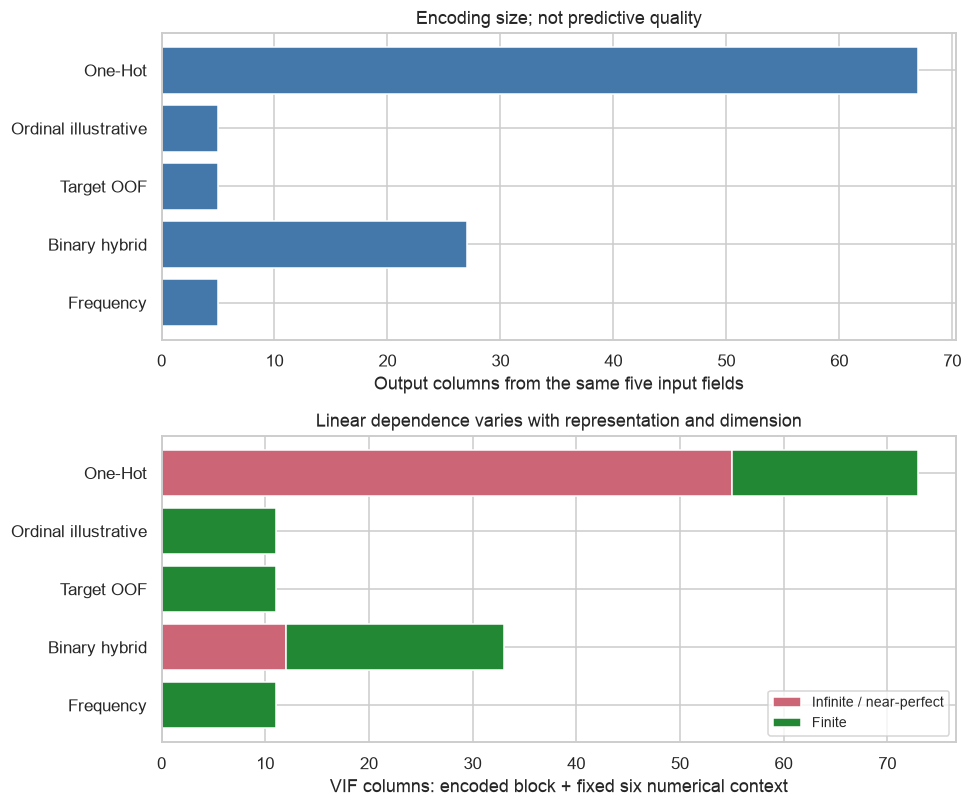

Decision: no encoding winner; retain original data and mappings for later fold-local evaluation.


In [10]:
encoding_findings = pd.DataFrame([
    {"Finding": "Common nominal comparison", "Evidence": f"{len(ENCODING_FEATURES)} fields; {len(train_index)} training rows; no ZIP/ID/target inputs", "Implication": "Retrospective comparison, not approved clinical baseline"},
    {"Finding": "High-cardinality binary scope", "Evidence": str(encoding_binary_widths), "Implication": "State bits plus unchanged low-cardinality One-Hot; arbitrary geometry"},
    {"Finding": "OOF leakage controls", "Evidence": f"{len(encoding_folds)} label-independent ZIP folds; all ZIP overlaps zero", "Implication": "Rebuild within each later model-training fold"},
    {"Finding": "Geographic design dependence", "Evidence": f"One-Hot scoped infinite/near-perfect VIF columns={int(encoding_vif_summary.loc['One-Hot','Infinite / near-perfect'])}", "Implication": "Reference coding alone does not remove cross-field dependence"},
    {"Finding": "Dimension versus sparse storage", "Evidence": f"One-Hot={encoding_comparison.loc['One-Hot','Output columns']} columns/{encoding_comparison.loc['One-Hot','Payload MiB']:.4f} MiB; binary hybrid={encoding_comparison.loc['Binary hybrid','Output columns']} columns/{encoding_comparison.loc['Binary hybrid','Payload MiB']:.4f} MiB", "Implication": "Fewer columns can consume more CSR payload when bit columns are denser"},
    {"Finding": "Existing numerical conditioning", "Evidence": f"69-column centered rank={int(encoding_full_rank.loc['Numerical 69 baseline','Centered predictor rank'])}; condition={encoding_full_rank.loc['Numerical 69 baseline','Condition nonconstant design']:.3g}", "Implication": "Full rank under the stated tolerance does not imply good conditioning; per-column VIF scope is limited"},
    {"Finding": "Frequency identity loss", "Evidence": f"{int(encoding_frequency_audit['Category identity collisions'].sum())} category-to-value collisions summed over fields", "Implication": "Compact encoding may discard distinctions"},
    {"Finding": "Unresolved prediction validity", "Evidence": "At-metastatic attributes; clinical dates/target anchors not established", "Implication": "No prospective or downstream-performance claim"}])
display(HTML('<div style="overflow:auto">'+encoding_findings.to_html(index=False)+'</div>'))
fig, axes = plt.subplots(2, 1, figsize=(9, 7.5))
axes[0].barh(ENCODING_ORDER, encoding_comparison.loc[ENCODING_ORDER, "Output columns"], color="#4477AA")
axes[0].invert_yaxis(); axes[0].set(xlabel="Output columns from the same five input fields", title="Encoding size; not predictive quality")
summary = encoding_vif_summary.loc[ENCODING_ORDER]
axes[1].barh(ENCODING_ORDER, summary["Infinite / near-perfect"], color="#CC6677", label="Infinite / near-perfect")
axes[1].barh(ENCODING_ORDER, summary["Total VIF columns"]-summary["Infinite / near-perfect"]-summary["Undefined constants"],
    left=summary["Infinite / near-perfect"], color="#228833", label="Finite")
axes[1].invert_yaxis(); axes[1].set(xlabel="VIF columns: encoded block + fixed six numerical context", title="Linear dependence varies with representation and dimension")
axes[1].legend(fontsize=9); plt.tight_layout(); plt.show()
print("Decision: no encoding winner; retain original data and mappings for later fold-local evaluation.")

## Conclusion

All five required methods and scoped VIF comparison are retained. Prospective availability
is unverified for at-metastatic payer/state and post-metastatic BMI; this remains a retrospective
supplied-table demonstration. Continue with [Stage 06](06_feature_selection.ipynb).

In [11]:
assert len(encoding_comparison) == 5 and encoding_comparison.Finite.all()
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_sha_before, "Raw CSV changed"
print(f"Completed five encodings of {len(ENCODING_FEATURES)} fields; {len(encoding_vif_full)} scoped VIF rows. No encoding winner declared.")

Completed five encodings of 5 fields; 145 scoped VIF rows. No encoding winner declared.
